# Example calculation of the diffusion coefficient

In [1]:
from vast_pea.lammps_traj import trajectory
from vast_pea.computers import compute_msd_cm
from vast_pea.masses import PCFF_MASSES, types_to_masses
from vast_pea.fitting import fit_diffusion

import matplotlib.pyplot as plt

## Read the trajectory

In [2]:
traj = trajectory(path="../../data/BER/save",
                  pattern="afd_325K_all.traj_data.atoms.nc",
                  filter_type=False,
                  filter=False,
                  restore=True,
                  verbose=True
                  )

	File list contains 1 files
	Trajectory done!


## Calculate the MSD

In [3]:
# a list of the types in the system in the order of their atom type id
types = ['c',  # 1
         'c1',  # 2
         'c2',  # 3
         'c3',  # 4
         'cp',  # 5
         'h',   # 6
         'hc',  # 7
         'hn',  # 8
         'ho2', # 9
         'nn',  # 10
         'oc',  # 11
         'oh',  # 12
         's1',  # 13
        ]
# transfer that list of types to a list of masses
masses = types_to_masses(types, PCFF_MASSES)

type_array = traj.get_atoms().type.isel(ts=0).values.astype(int) # list of every atom's type

msd = compute_msd_cm(
    positions=traj.get_unwrapped(), # position of atoms unwrapped
    types=type_array, # type for every atom
    masses=masses # mass for every type
)

## Plot the MSD in log-log scale

Text(0, 0.5, 'MSD (Angstrom^2)')

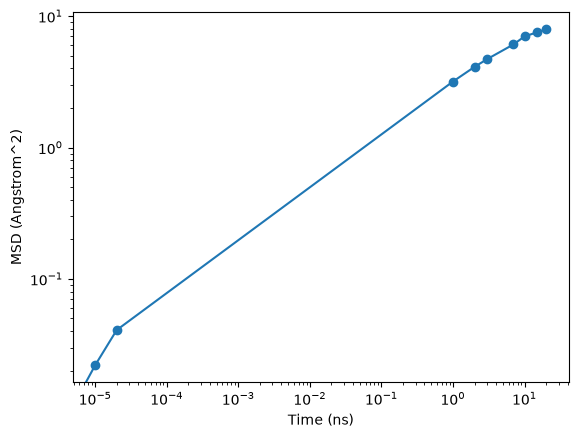

In [4]:
plt.plot(traj.timesteps/1e6 - 1, msd, 'o-')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time (ns)')
plt.ylabel('MSD (Angstrom^2)')

Normally we would get something smoother and similar to Figure 5c of the publication.
We would then identify the free diffusion regime from the linear region of this graph at long times.
In the publication, a regression is done on the last 5ns of this MSD graph to obtain the diffusion coefficient.
In the case of this example, the last 3 data points (10ns) are taken instead for simplicity.

## Calculate the diffusion coefficient

In [ ]:
diff = fit_diffusion(x=(traj.timesteps/1e6 - 1)[-3:], # x (time) data using the last 3 points
                     y=msd[-3:], # y (msd) using the last 3 points
                     initial_units={'dist':'angstrom', 'time':'ns'}, # units of distance and time as given for x and y
                     final_units=  {'dist':'cm',       'time':'s'}, # units of distance and time as wanted for the diffusion coefficient
                     verbose=True # print fit information
                     )

Fitting Diffusion Coefficient :
	a : 0.0937 ± 0.0065 angstrom^2 / ns
	b : 6.09 ± 0.10 angstrom
	R^2 : 1.00
	Diffusion coefficient : 1.56084921715e-09 ± 1.07865546082e-10 cm^2 / s
